In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import mysql.connector as conn
import numpy as np
import pandas as pd; pd.set_option("display.float_format","{:,.2f}".format)
import seaborn as sns; sns.set_theme()
import sqlalchemy

from dotenv import load_dotenv
from pca import pca
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sqlalchemy.sql import text
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

In [2]:
# Takes environment variables from .env.
load_dotenv()

# Credentials for local PostgreSQL database.
pg_host = "localhost"
pg_database = "paid_content"
pg_schema = "user_profile"
pg_table = "activity"
pg_user = "postgres"
pg_pass = os.environ["POSTGRES_PASSWORD"]
pg_port = 5432

# Credentials for internal Delfi database.
dlf_name_articles = "delfi_articles"
dlf_name_paywall = "paywall"
dlf_host = os.environ["DELFI_DB_HOST"]
dlf_user = os.environ["DELFI_DB_USER"]
dlf_pass = os.environ["DELFI_DB_PASSWORD"]
dlf_port = os.environ["DELFI_DB_PORT"]

In [3]:
# Create connection to internal Delfi database.
dlf_paywall_db = conn.connect(
    host=dlf_host,
    port=dlf_port,
    user=dlf_user,
    password=dlf_pass,
    database=dlf_name_paywall
)

In [4]:
# Get paid content users' activity data.
postgresql_url = f"postgresql+psycopg2://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_database}"

engine = sqlalchemy.create_engine(postgresql_url)

activity_query = text("SELECT * FROM user_profile.activity")

with engine.connect().execution_options(autocommit=True) as conn:
    activity_query_sql = conn.execute(activity_query)

activity_query_data = pd.DataFrame(activity_query_sql.fetchall())

In [5]:
activity_query_data["date"] = activity_query_data["timestamp"].dt.date

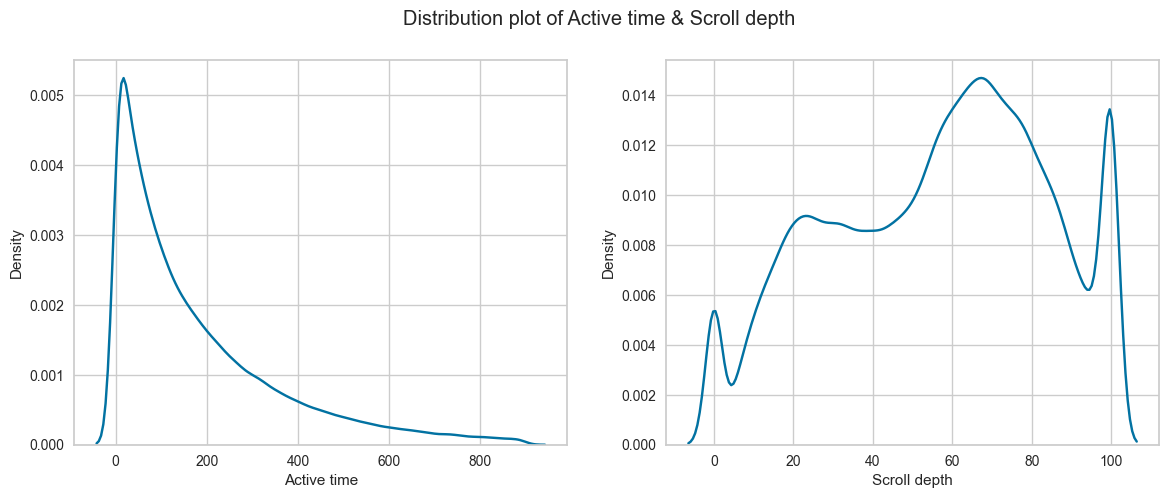

In [6]:
fig, axes = plt.subplots(ncols=2, figsize=(14,5))
sns.kdeplot(ax=axes[0], data=activity_query_data, x="active_time")
sns.kdeplot(ax=axes[1], data=activity_query_data, x="scroll_depth")
fig.suptitle("Distribution plot of Active time & Scroll depth")
axes[0].set_xlabel("Active time")
axes[1].set_xlabel("Scroll depth")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density");

Kadangi Active time ir Scroll depth dydžių pasiskirstymas yra nevienodas, o Active time atveju jis yra labai "skewed", todėl "vidutinei" reikšmei rasti naudosime ne vidurkį, o medianą.

In [7]:
data_agg = activity_query_data.groupby("user_delfi_id").agg(
    frequency=("date", lambda x: x.nunique()),
    volume=("article_id", lambda x: x.nunique()),
    last_visit=("date", "max"),
    median_active_time=("active_time", "median"),
    avg_scroll_depth=("scroll_depth", "mean")
).reset_index()

In [8]:
anchor_date = pd.to_datetime("2023-02-27").date()
data_agg["recency"] = (anchor_date - data_agg["last_visit"]).dt.days

data_agg["rfv_score"] = (data_agg["frequency"] * np.sqrt((data_agg["volume"]))) / (data_agg["recency"] + 1)

In [9]:
# Get User ID for matching with User Delfi ID.
user_id_query = """
    SELECT id, delfi_id
    FROM paywall.users
    WHERE delfi_id IS NOT NULL
    """

user_id_data = pd.read_sql(user_id_query, dlf_paywall_db)

In [10]:
data_agg = data_agg.merge(user_id_data, how="left", left_on="user_delfi_id", right_on="delfi_id").rename(columns={"id": "user_id"})

In [11]:
# Get users IDs that matches main parameters: included in count and paid subscription. 
user_sub_data_query = """
    SELECT DISTINCT(user_id)
    FROM paywall.user_subscriptions AS US
    LEFT JOIN paywall.subscriptions AS S
    ON US.subscription_id = S.id
    WHERE S.included_in_count = 1
    AND S.service_id IN (1, 3, 4, 9, 10)
    AND valid_till > "2022-12-31 23:59:59"
    AND sf_category = "Paid subscriptions"
    """

user_sub_data_query = pd.read_sql(user_sub_data_query, dlf_paywall_db)

In [12]:
data_agg = data_agg.merge(user_sub_data_query, how="inner", on="user_id")

In [13]:
# Get transactions information about each user.
users_transactions_query = """
    SELECT user_id, COUNT(id) AS total_transactions, SUM(sum) AS total_amount
    FROM paywall.transactions
    WHERE completion_timestamp IS NOT NULL
    GROUP BY user_id
    """

users_transactions_data = pd.read_sql(users_transactions_query, dlf_paywall_db)

In [14]:
data_agg = data_agg.merge(users_transactions_data, how="left", on="user_id")
data_agg = data_agg.dropna().reset_index().drop(columns="index")

In [15]:
clustering_data = data_agg.drop(columns=["user_delfi_id", "last_visit", "rfv_score", "user_id", "delfi_id"])

In [16]:
scaler = StandardScaler()
clustering_data_scaled = scaler.fit_transform(clustering_data)

# Elbow method

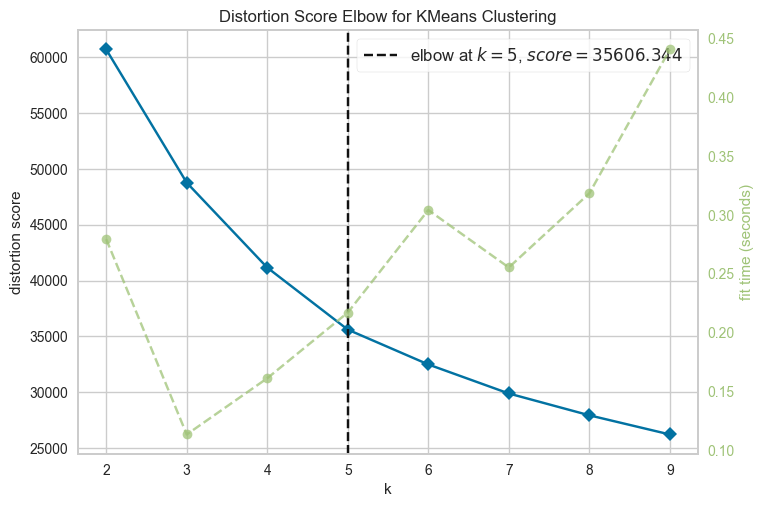

In [17]:
km = KMeans(random_state=42)
visualizer = KElbowVisualizer(km, k=(2,10))

visualizer.fit(clustering_data_scaled)
visualizer.show();

In [18]:
kmeans = KMeans(5)
kmeans.fit(clustering_data_scaled)
kmeans.cluster_centers_.shape

print(f"Clusters: {kmeans.cluster_centers_.shape[0]}")
print(f"Features: {kmeans.cluster_centers_.shape[1]}")

Clusters: 5
Features: 7


In [19]:
cluster_centers = pd.DataFrame(data=kmeans.cluster_centers_, columns=clustering_data.columns)

# Inverse scaling transformation
cluster_centers = scaler.inverse_transform(cluster_centers)
cluster_centers = pd.DataFrame(data=cluster_centers, columns=clustering_data.columns)
cluster_centers

,frequency,volume,median_active_time,avg_scroll_depth,recency,total_transactions,total_amount
0,38.74,91.64,146.65,57.56,0.81,4.35,53.23
1,8.96,13.74,118.44,54.02,10.73,22.53,110.94
2,3.42,4.71,339.72,75.08,24.05,5.48,49.44
3,10.36,15.23,111.55,55.05,4.92,3.50,47.37
4,2.45,3.15,64.92,34.30,30.88,4.92,44.93


In [20]:
# Attach Cluster, User ID and RFV score columns to main dataframe.
labels = kmeans.labels_

clustered_data = clustering_data.join(pd.DataFrame({"cluster": labels}))
clustered_data["cluster"] = clustered_data["cluster"].astype("str")

clustered_data = clustered_data.join(data_agg[["user_id", "rfv_score"]])
clustered_data["user_id"] = clustered_data["user_id"].astype("int64").astype("str")

clustered_data.head()

,frequency,volume,median_active_time,avg_scroll_depth,recency,total_transactions,total_amount,cluster,user_id,rfv_score
0,35,60,258.00,60.79,2,2.00,48.00,0,14449,90.37
1,25,36,86.00,49.35,1,13.00,88.89,1,5856,75.00
2,5,7,55.00,89.14,3,27.00,101.75,1,56979,3.31
3,26,50,56.50,49.33,0,3.00,73.98,3,56747,183.85
4,14,19,158.00,74.16,5,2.00,40.00,3,99419,10.17


In [21]:
pca = PCA(n_components=2)
principal_comp = pca.fit_transform(clustering_data_scaled)

pca_df = pd.DataFrame(data=principal_comp, columns=["PCA1", "PCA2"])
pca_df = pd.concat([pca_df, pd.DataFrame({"cluster": labels})], axis=1)
pca_df.head()

,PCA1,PCA2,cluster
0,2.16,-0.30,0
1,0.87,1.36,1
2,-0.64,2.66,1
3,1.39,0.24,3
4,0.45,-0.71,3


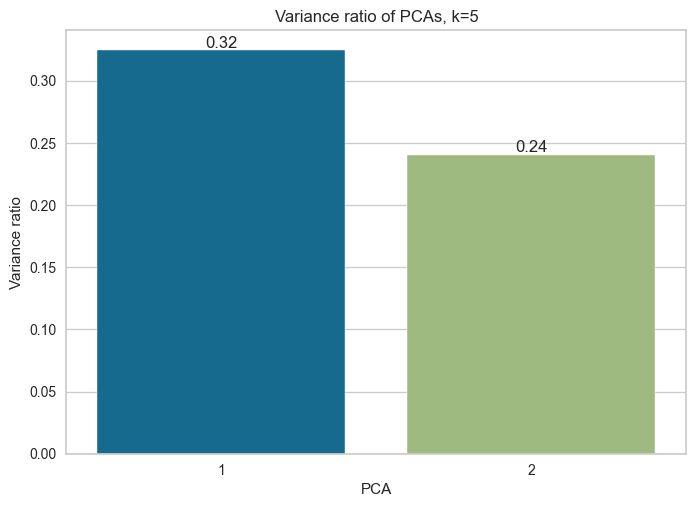

In [22]:
ax = sns.barplot(x=np.arange(pca.n_components_) + 1, y=pca.explained_variance_ratio_)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Variance ratio of PCAs, k=5")
plt.xlabel("PCA")
plt.ylabel("Variance ratio");

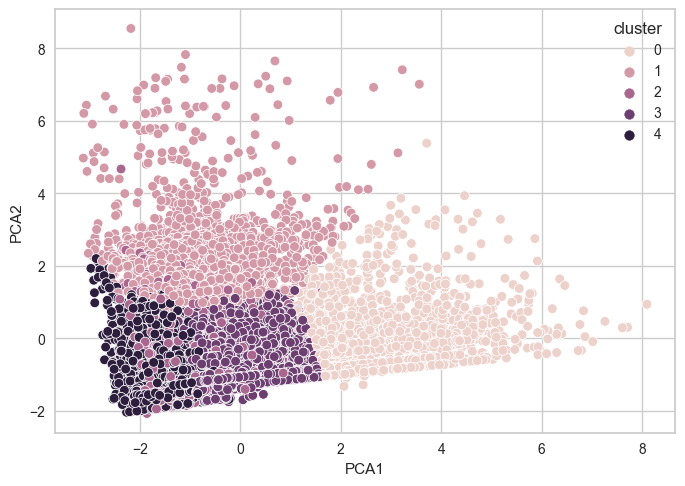

In [23]:
sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="cluster");

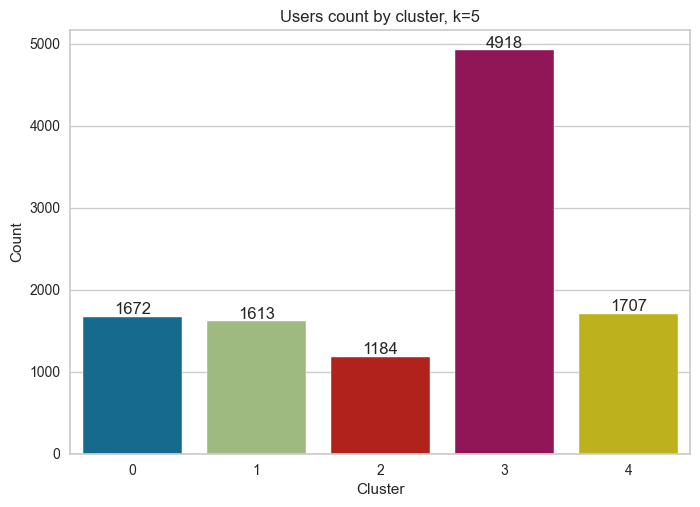

In [24]:
ax = sns.countplot(x=clustered_data["cluster"], order=["0", "1", "2", "3", "4"])
ax.bar_label(ax.containers[0])
plt.title("Users count by cluster, k=5")
plt.xlabel("Cluster")
plt.ylabel("Count");

In [25]:
histogram_data = clustered_data[["frequency", "volume", "median_active_time", "recency", "total_transactions", "total_amount", "rfv_score"]]

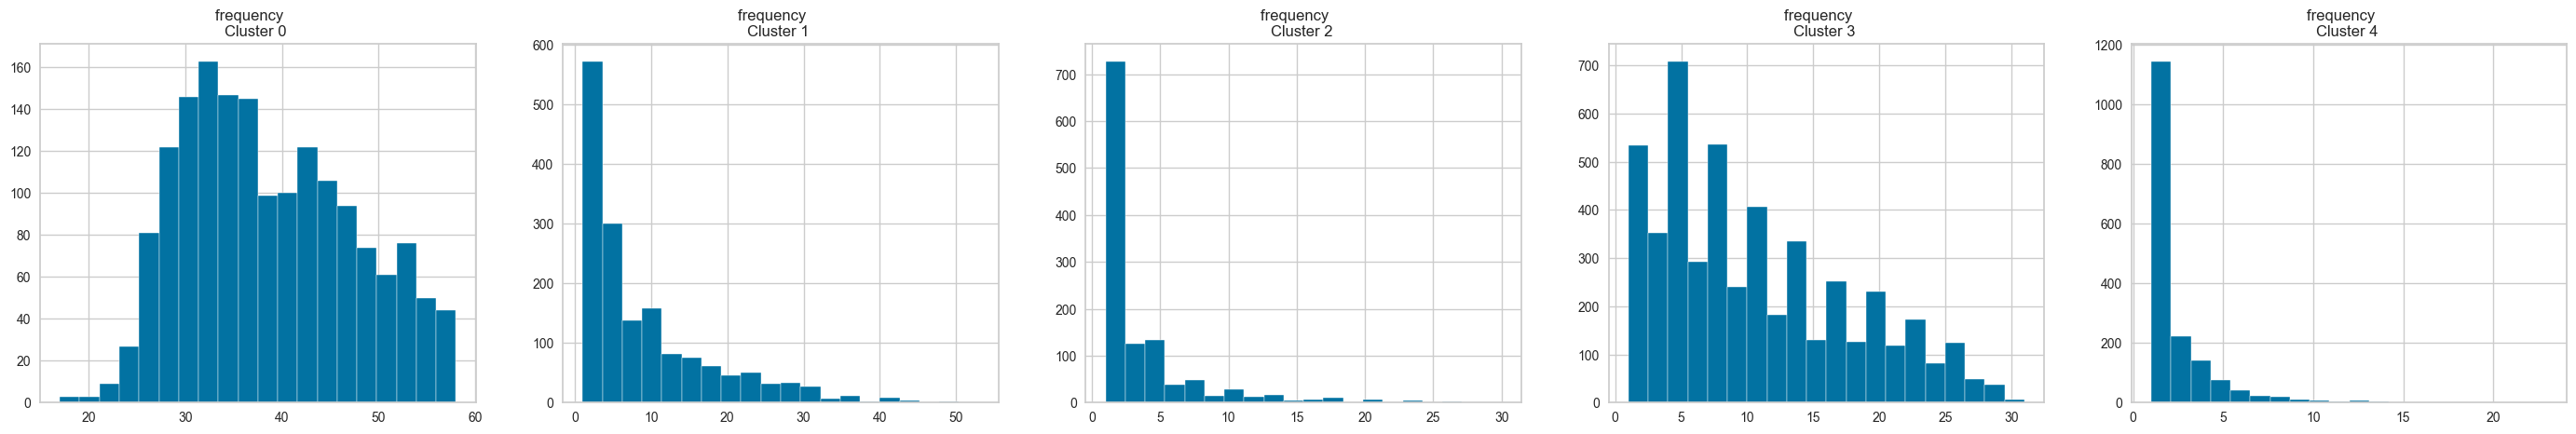

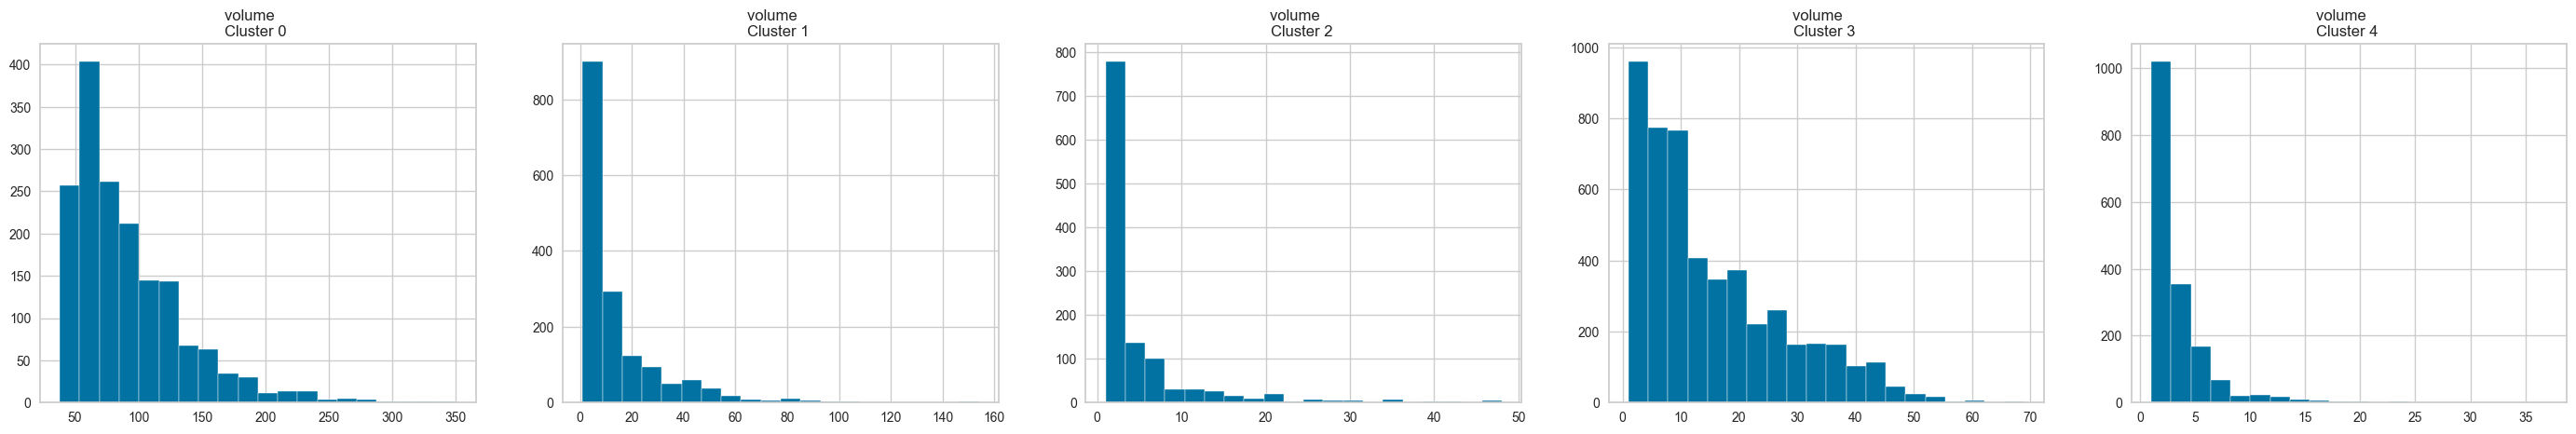

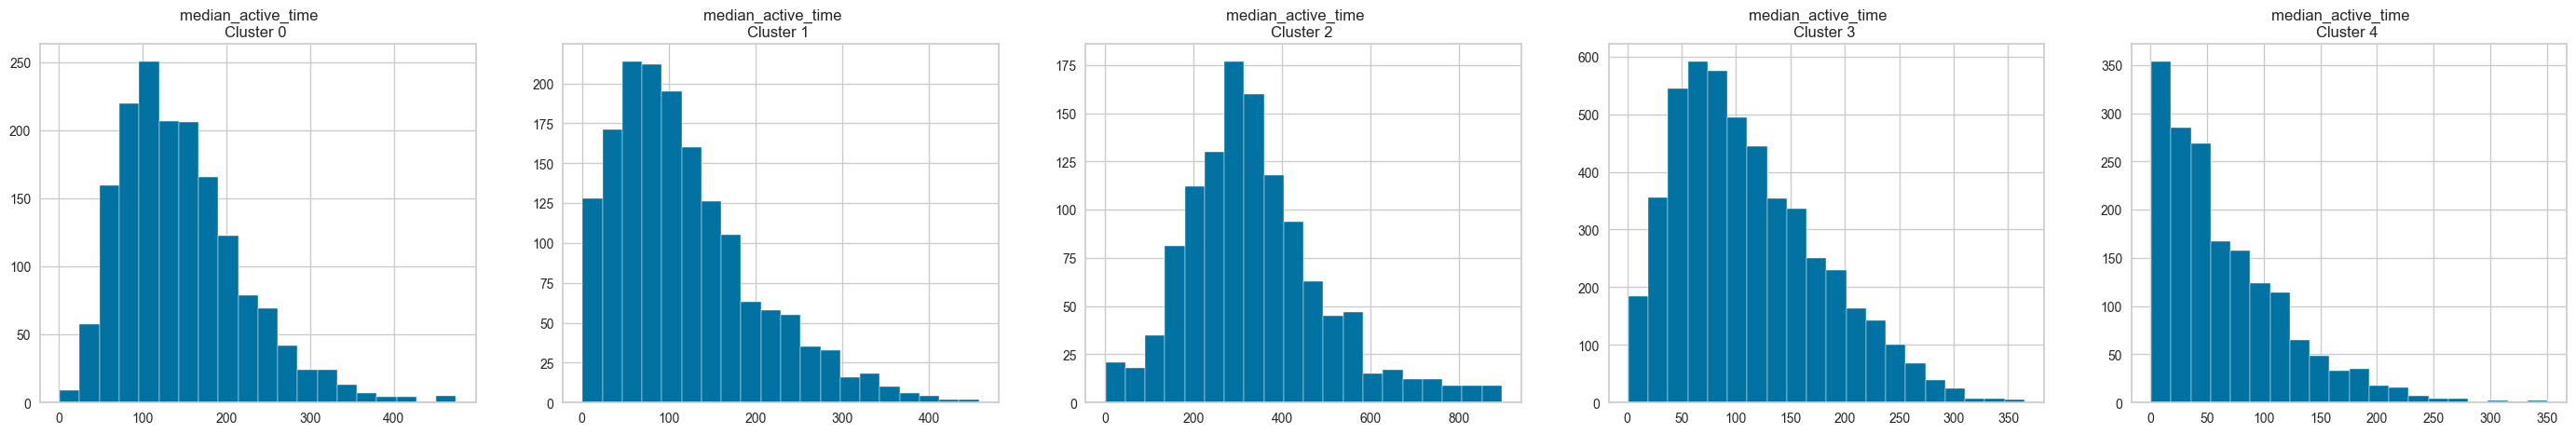

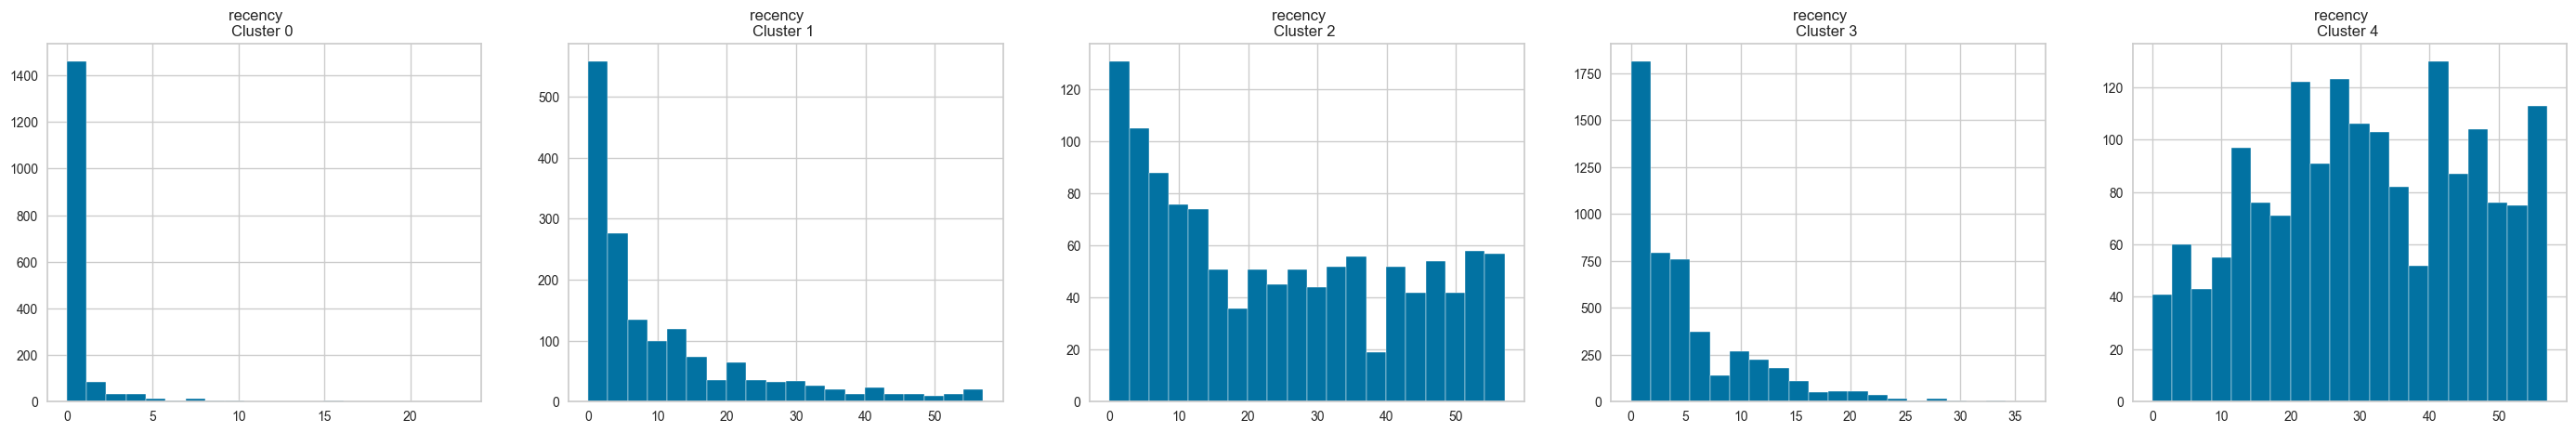

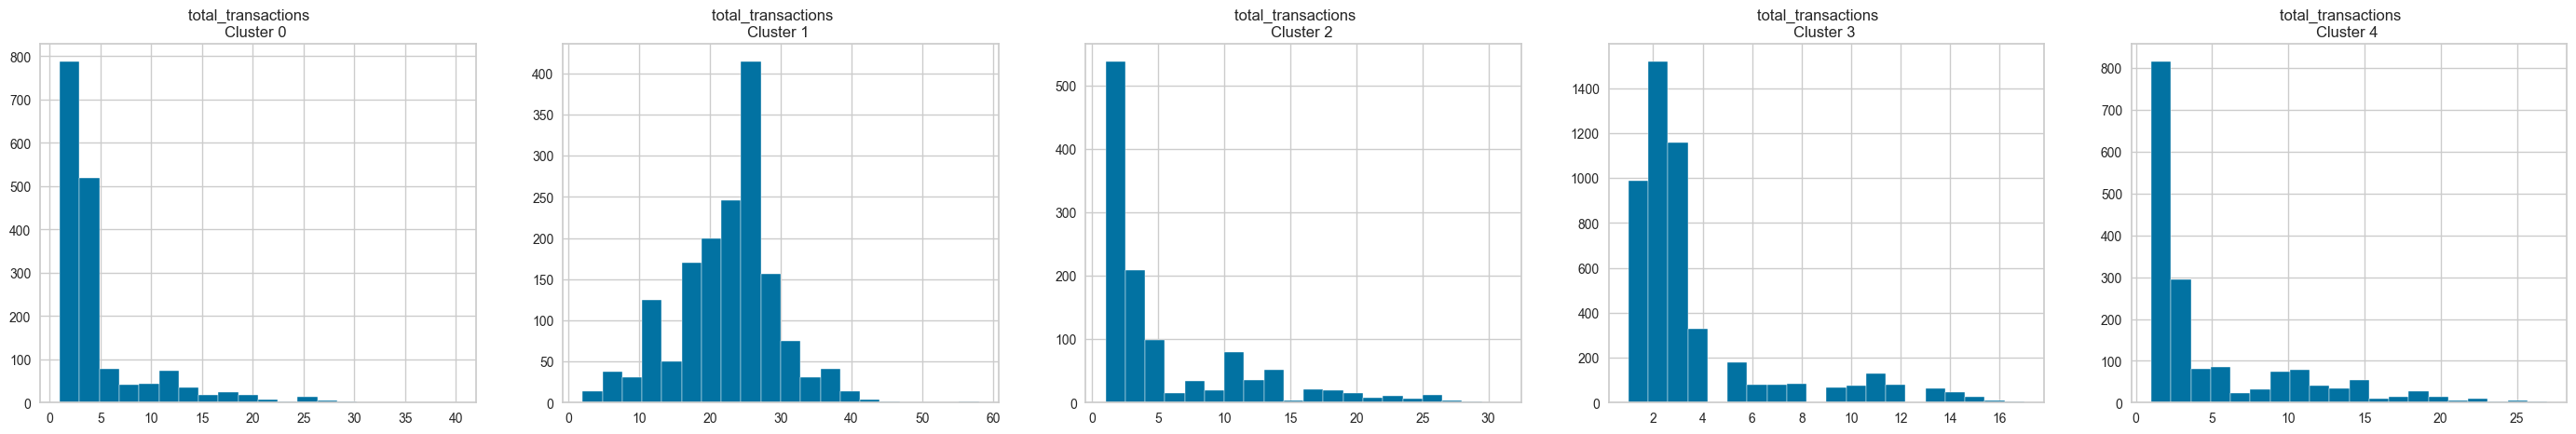

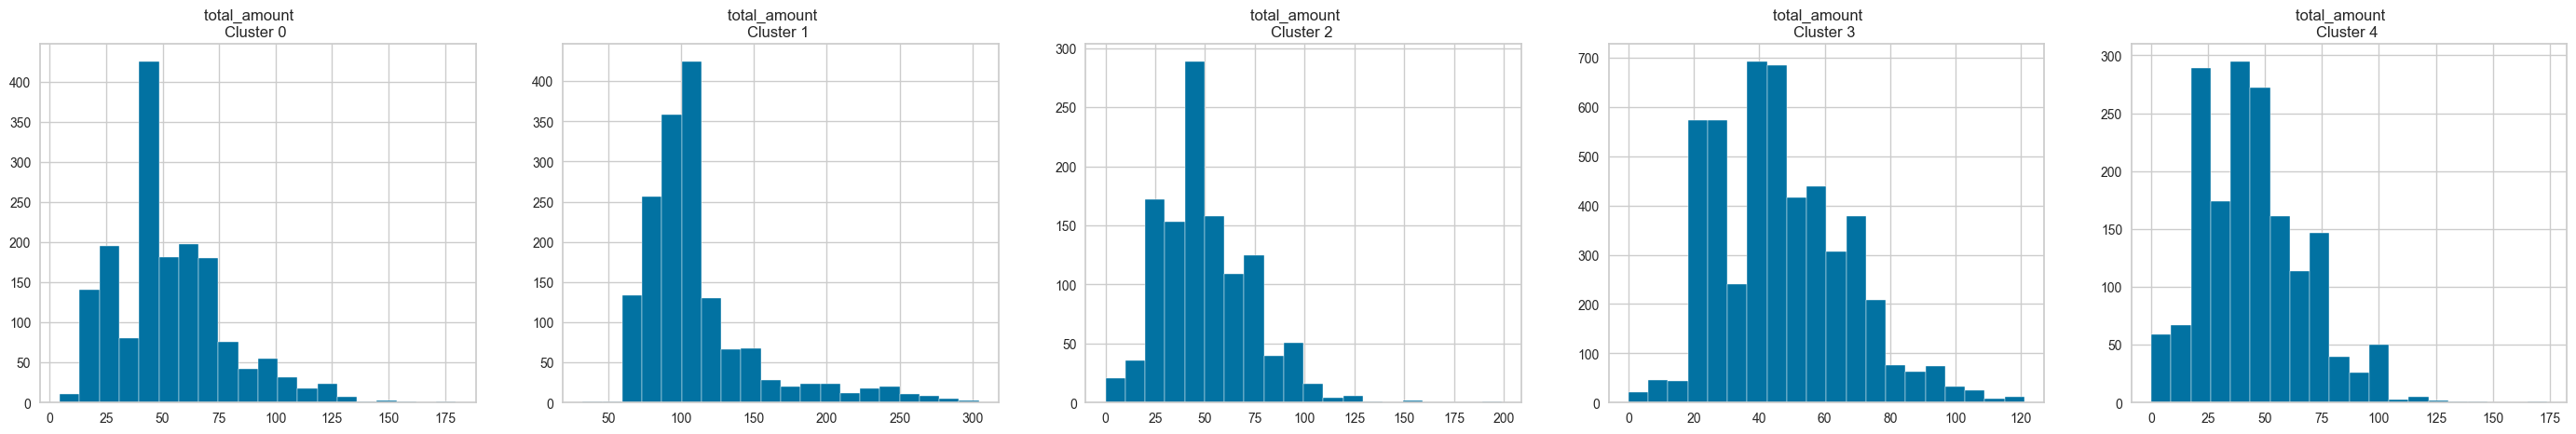

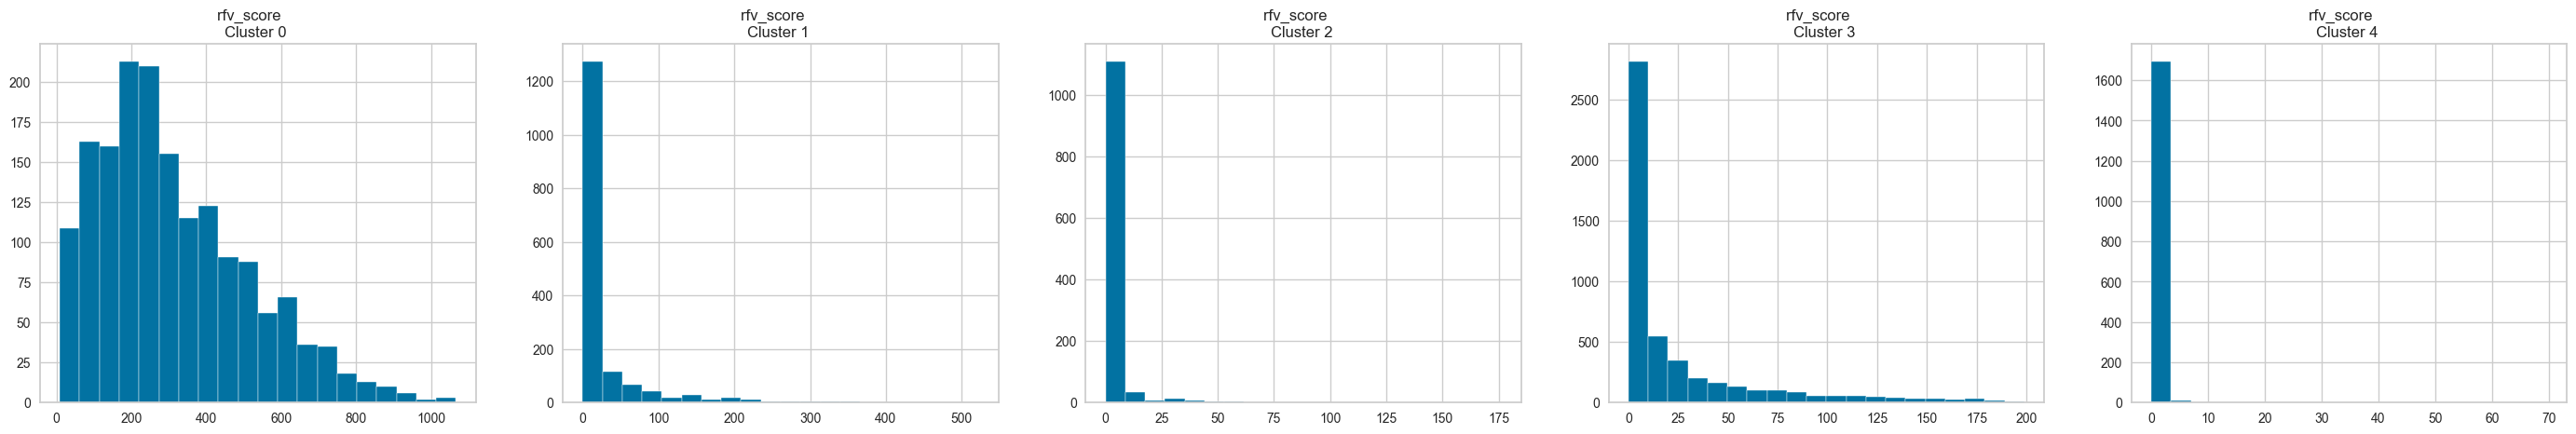

In [26]:
# Plot the histogram of various clusters.
for i in histogram_data.columns:
  plt.figure(figsize = (35, 5))
  for j in range(5):
    plt.subplot(1,5,j+1)
    cluster = clustered_data[clustered_data["cluster"] == str(j)]
    cluster[i].hist(bins = 20)
    plt.title("{}    \nCluster {} ".format(i,j))
  
  plt.show()

In [27]:
pd.DataFrame({
    "Users": clustered_data.groupby("cluster")["user_id"].count(),
    "Share": clustered_data.groupby("cluster")["user_id"].count() / clustered_data["user_id"].count() * 100,
    "RFV": clustered_data.groupby("cluster")["rfv_score"].median(),
    "Frequency": clustered_data.groupby("cluster")["frequency"].median(),
    "Recency": clustered_data.groupby("cluster")["recency"].median(),
    "Volume": clustered_data.groupby("cluster")["volume"].median(),
    "Active time": clustered_data.groupby("cluster")["median_active_time"].median(),
    "Scroll depth": clustered_data.groupby("cluster")["avg_scroll_depth"].median(),
    "Transactions": clustered_data.groupby("cluster")["total_transactions"].median(),
    "Amount": clustered_data.groupby("cluster")["total_amount"].median(),
}).set_axis(["Cluster: 0", "Cluster: 1", "Cluster: 2", "Cluster: 3", "Cluster: 4"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Cluster: 0,1672,15.07,266.30,37.00,0.00,79.00,134.00,58.27,3.00,48.00
Cluster: 1,1613,14.54,2.60,6.00,5.00,7.00,100.00,55.04,24.00,100.85
Cluster: 2,1184,10.67,0.15,2.00,21.50,2.00,319.00,74.50,3.00,44.98
Cluster: 3,4918,44.33,6.85,9.00,3.00,11.00,99.00,55.00,2.00,43.99
Cluster: 4,1707,15.39,0.09,2.00,30.00,2.00,50.50,34.50,3.00,43.00


# Silhouette plot

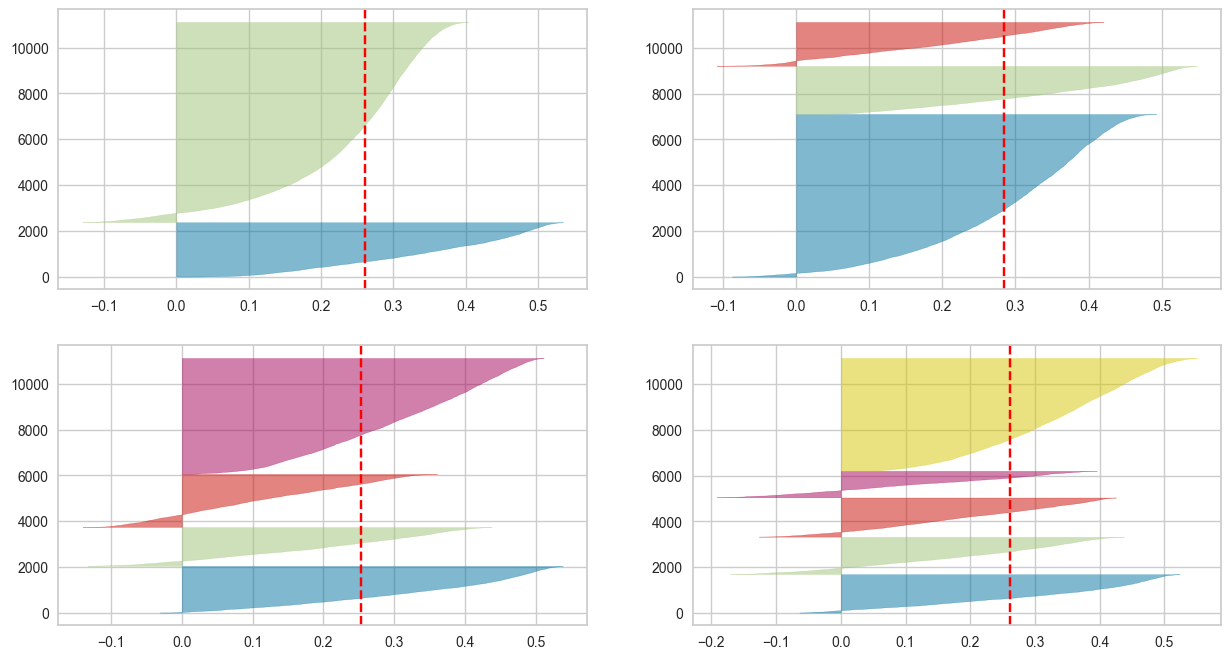

In [28]:
fig, ax = plt.subplots(2, 2, figsize=(15,8))

for i in [2, 3, 4, 5]:
    km = KMeans(n_clusters=i, init="k-means++", n_init=10, max_iter=100, random_state=42)
    q, mod = divmod(i, 2)
    
    visualizer = SilhouetteVisualizer(km, colors="yellowbrick", ax=ax[q-1][mod])
    visualizer.fit(clustering_data_scaled)

Explaining the Silhouette score: the best value is 1 and the worst value is -1. Values near 0 indicate overlapping clusters. Negative values generally indicate that a sample has been assigned to the wrong cluster, as a different cluster is more similar.

- For a particular K, all the clusters should have a Silhouette score more than the average score of the dataset (represented by a red dotted line). The x-axis represents the Silhouette score.
- There should not be wide fluctuations in the size of the clusters. The width of the clusters represents the number of data points.

In [29]:
kmeans = KMeans(3)
kmeans.fit(clustering_data_scaled)
kmeans.cluster_centers_.shape

print(f"Clusters: {kmeans.cluster_centers_.shape[0]}")
print(f"Features: {kmeans.cluster_centers_.shape[1]}")

Clusters: 3
Features: 7


In [30]:
cluster_centers = pd.DataFrame(data=kmeans.cluster_centers_, columns=clustering_data.columns)

# Inverse scaling transformation
cluster_centers = scaler.inverse_transform(cluster_centers)
cluster_centers = pd.DataFrame(data=cluster_centers, columns=clustering_data.columns)
cluster_centers

,frequency,volume,median_active_time,avg_scroll_depth,recency,total_transactions,total_amount
0,7.91,12.02,132.94,54.03,13.33,21.57,106.73
1,35.89,81.58,143.75,57.44,0.91,4.25,52.87
2,6.76,9.46,133.13,53.34,13.65,3.61,45.36


In [31]:
# Attach Cluster, User ID and RFV score columns to main dataframe.
labels = kmeans.labels_

clustered_data = clustering_data.join(pd.DataFrame({"cluster": labels}))
clustered_data["cluster"] = clustered_data["cluster"].astype("str")

clustered_data = clustered_data.join(data_agg[["user_id", "rfv_score"]])
clustered_data["user_id"] = clustered_data["user_id"].astype("int64").astype("str")

clustered_data.head()

,frequency,volume,median_active_time,avg_scroll_depth,recency,total_transactions,total_amount,cluster,user_id,rfv_score
0,35,60,258.00,60.79,2,2.00,48.00,1,14449,90.37
1,25,36,86.00,49.35,1,13.00,88.89,0,5856,75.00
2,5,7,55.00,89.14,3,27.00,101.75,0,56979,3.31
3,26,50,56.50,49.33,0,3.00,73.98,1,56747,183.85
4,14,19,158.00,74.16,5,2.00,40.00,2,99419,10.17


In [32]:
pca = PCA(n_components=2)
principal_comp = pca.fit_transform(clustering_data_scaled)

pca_df = pd.DataFrame(data=principal_comp, columns=["PCA1", "PCA2"])
pca_df = pd.concat([pca_df, pd.DataFrame({"cluster": labels})], axis=1)
pca_df.head()

,PCA1,PCA2,cluster
0,2.16,-0.30,1
1,0.87,1.36,0
2,-0.64,2.66,0
3,1.39,0.24,1
4,0.45,-0.71,2


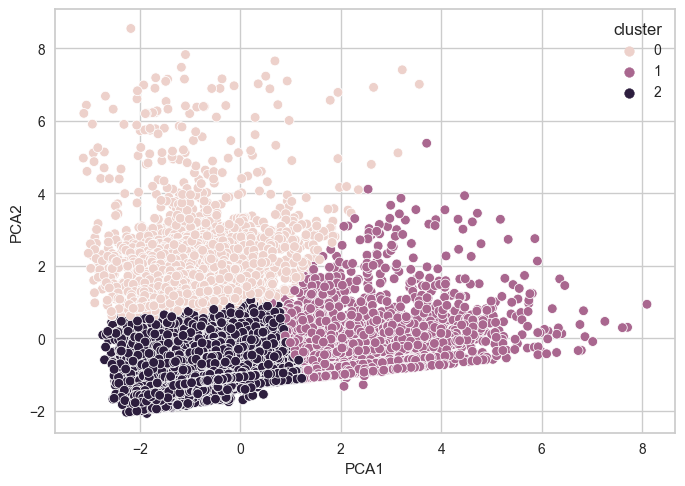

In [33]:
sns.scatterplot(data=pca_df, x="PCA1", y="PCA2", hue="cluster");

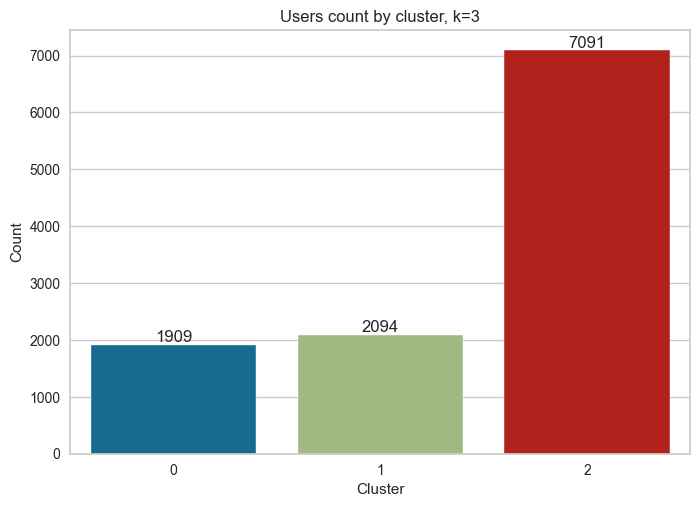

In [34]:
ax = sns.countplot(x=clustered_data["cluster"], order=["0", "1", "2"])
ax.bar_label(ax.containers[0])
plt.title("Users count by cluster, k=3")
plt.xlabel("Cluster")
plt.ylabel("Count");

In [35]:
pd.DataFrame({
    "Users": clustered_data.groupby("cluster")["user_id"].count(),
    "Share": clustered_data.groupby("cluster")["user_id"].count() / clustered_data["user_id"].count() * 100,
    "RFV": clustered_data.groupby("cluster")["rfv_score"].median(),
    "Frequency": clustered_data.groupby("cluster")["frequency"].median(),
    "Recency": clustered_data.groupby("cluster")["recency"].median(),
    "Volume": clustered_data.groupby("cluster")["volume"].median(),
    "Active time": clustered_data.groupby("cluster")["median_active_time"].median(),
    "Scroll depth": clustered_data.groupby("cluster")["avg_scroll_depth"].mean(),
    "Transactions": clustered_data.groupby("cluster")["total_transactions"].median(),
    "Amount": clustered_data.groupby("cluster")["total_amount"].median(),
}).set_axis(["Cluster: 0", "Cluster: 1", "Cluster: 2"], axis="index")

,Users,Share,RFV,Frequency,Recency,Volume,Active time,Scroll depth,Transactions,Amount
Cluster: 0,1909,17.21,1.44,4.00,6.00,6.00,103.00,54.03,22.00,97.76
Cluster: 1,2094,18.88,214.85,34.00,0.00,68.00,131.50,57.45,3.00,48.00
Cluster: 2,7091,63.92,1.52,5.00,7.00,6.00,100.00,53.34,2.00,43.99


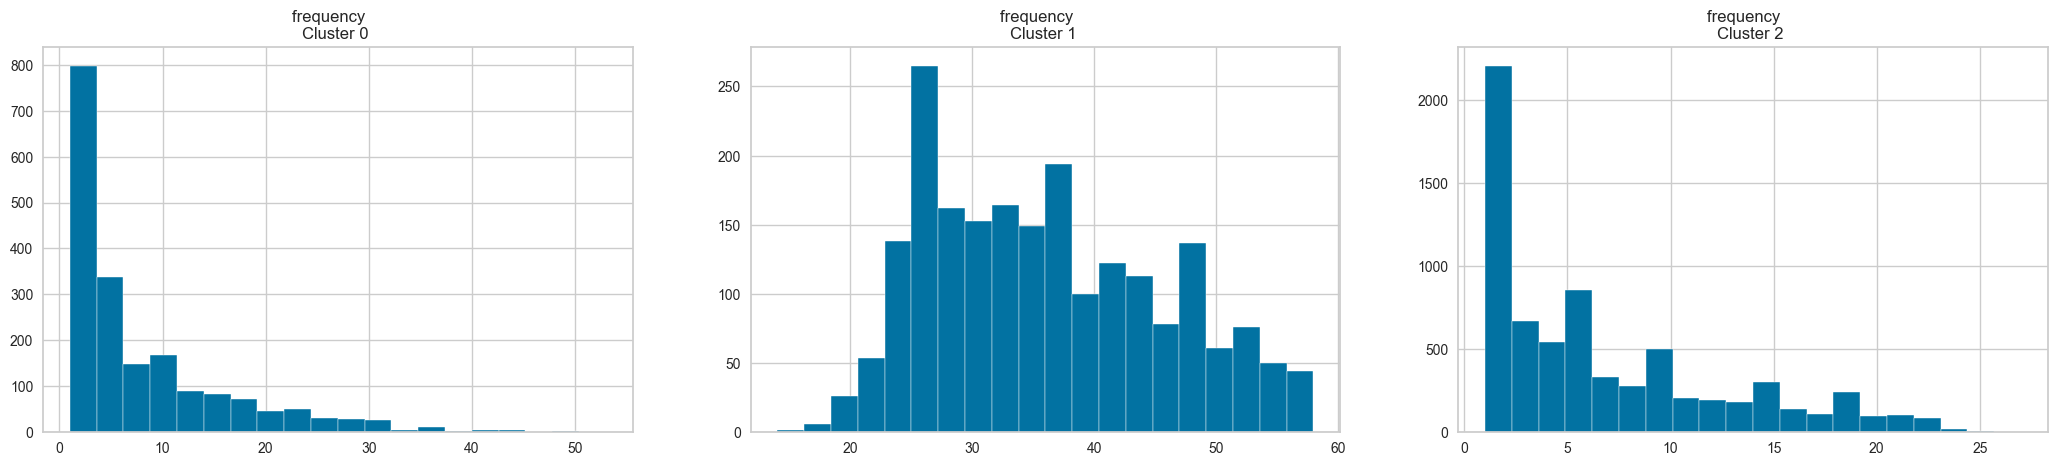

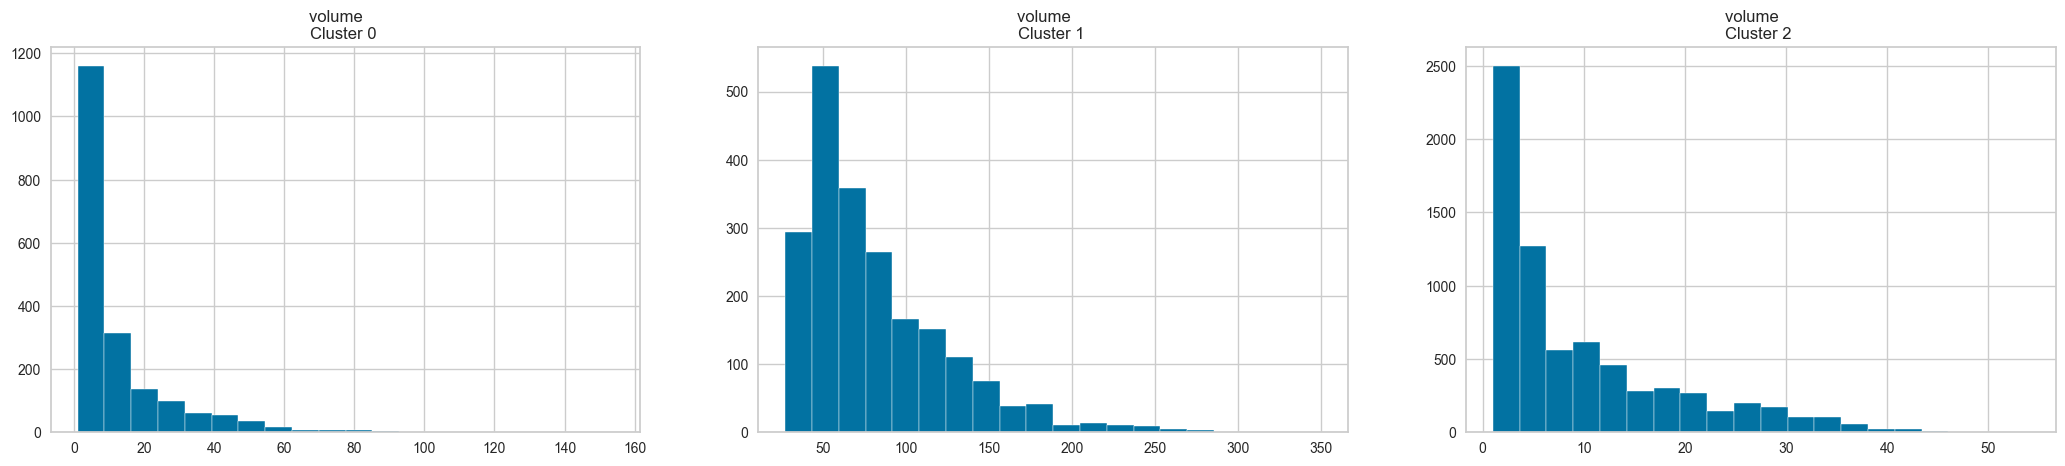

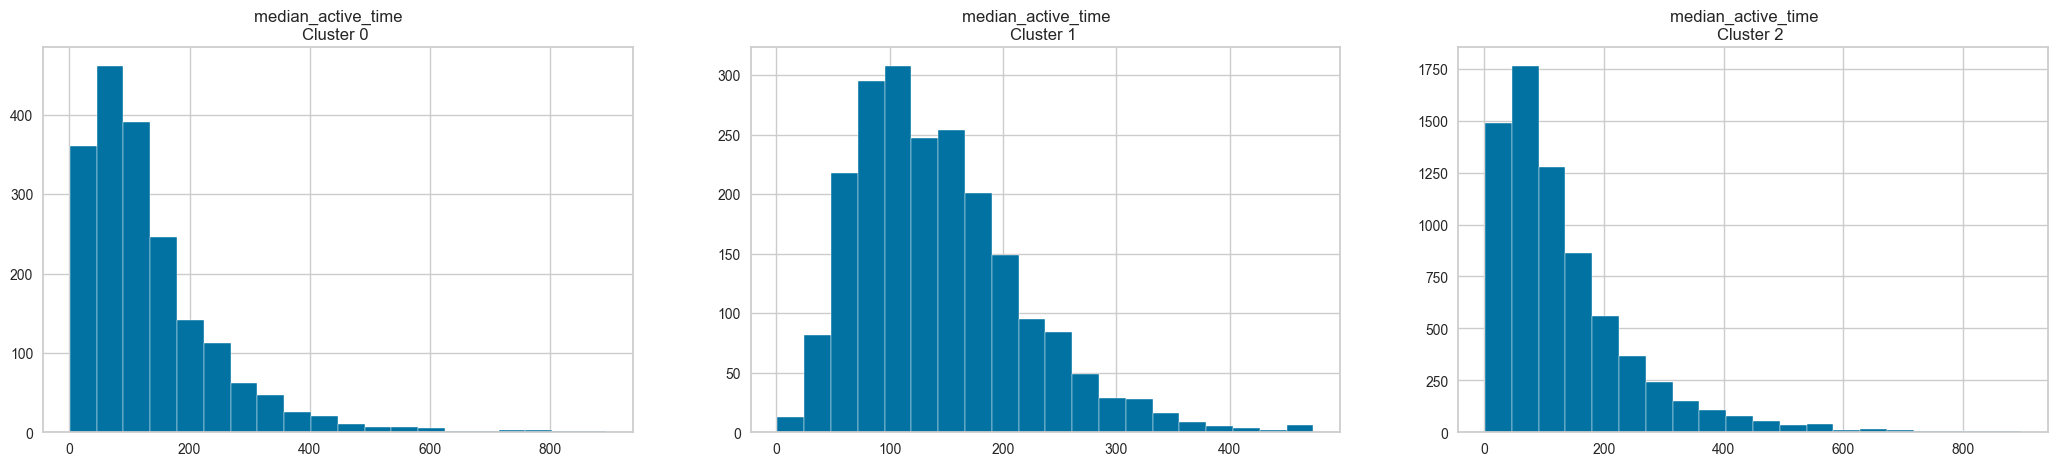

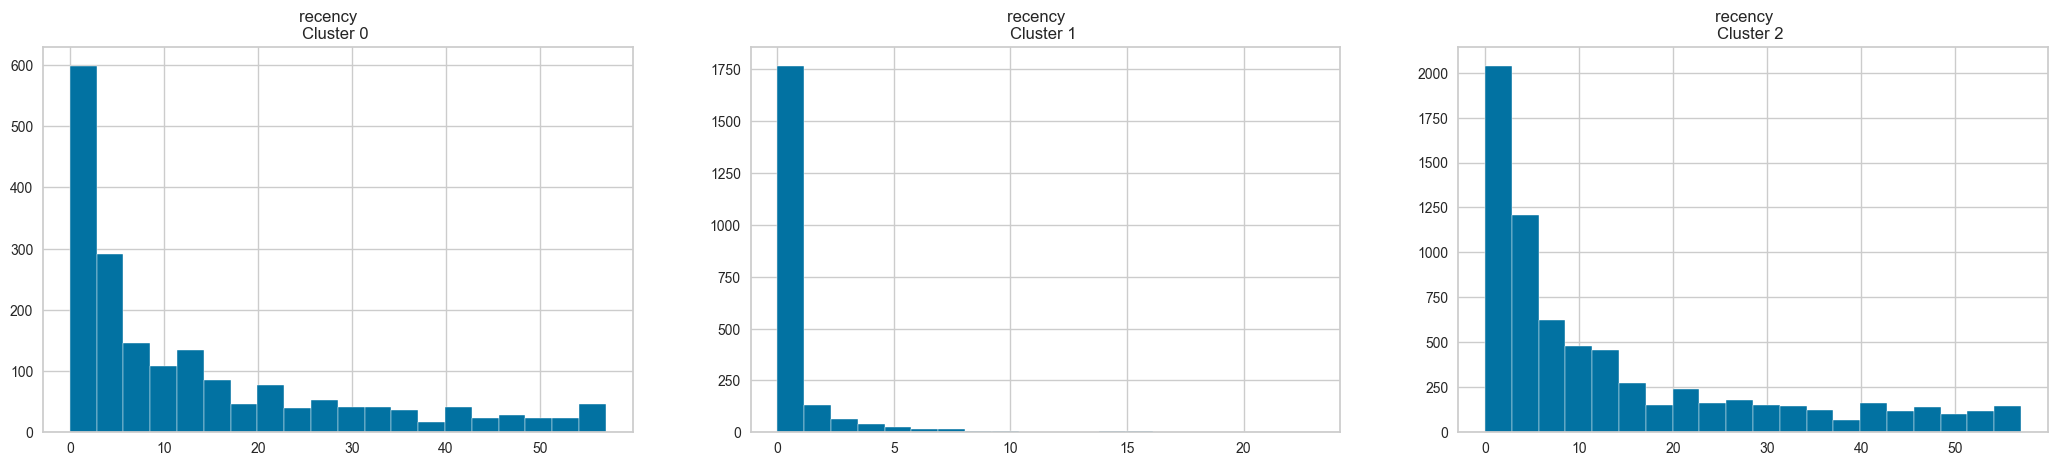

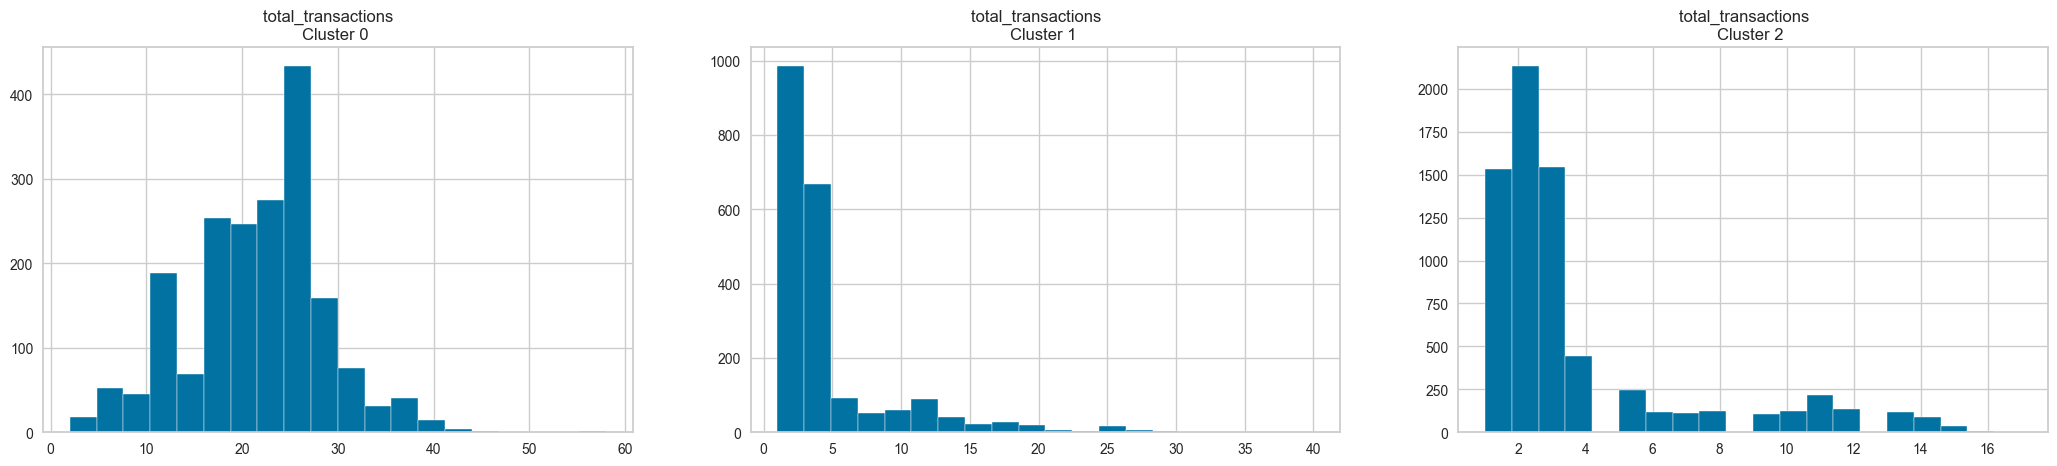

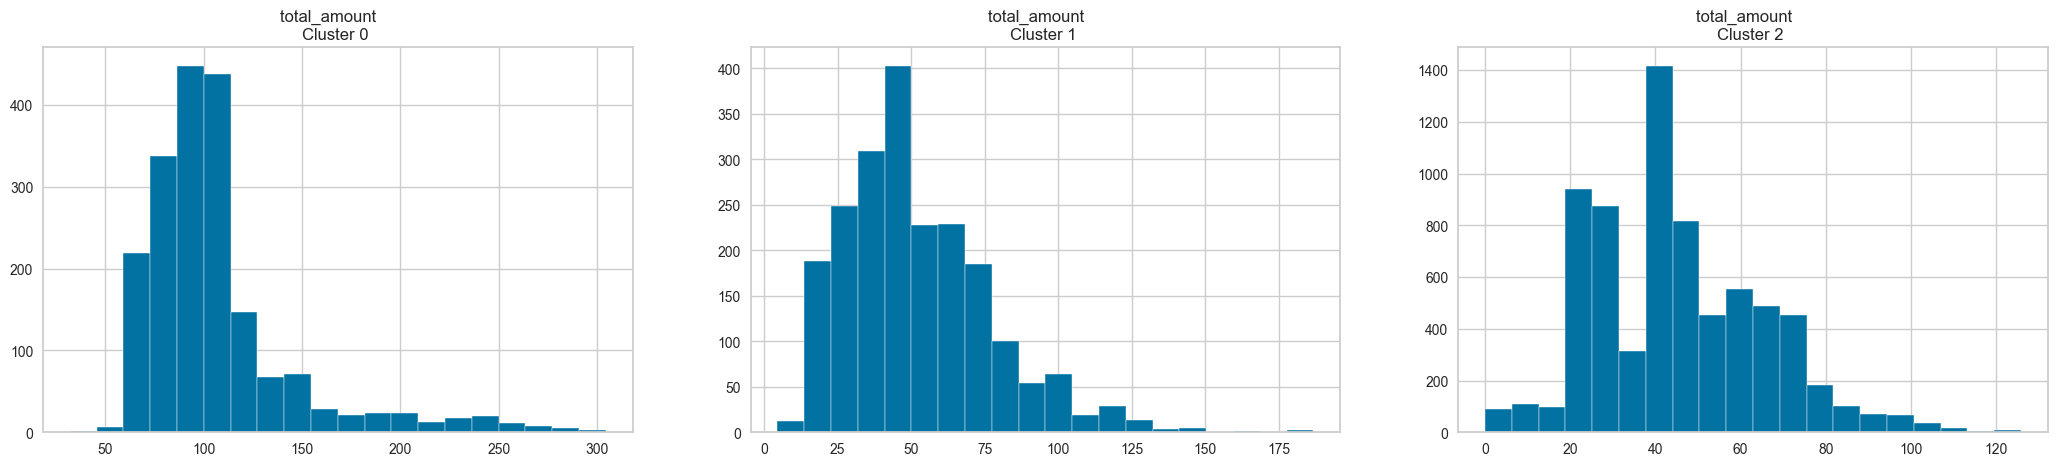

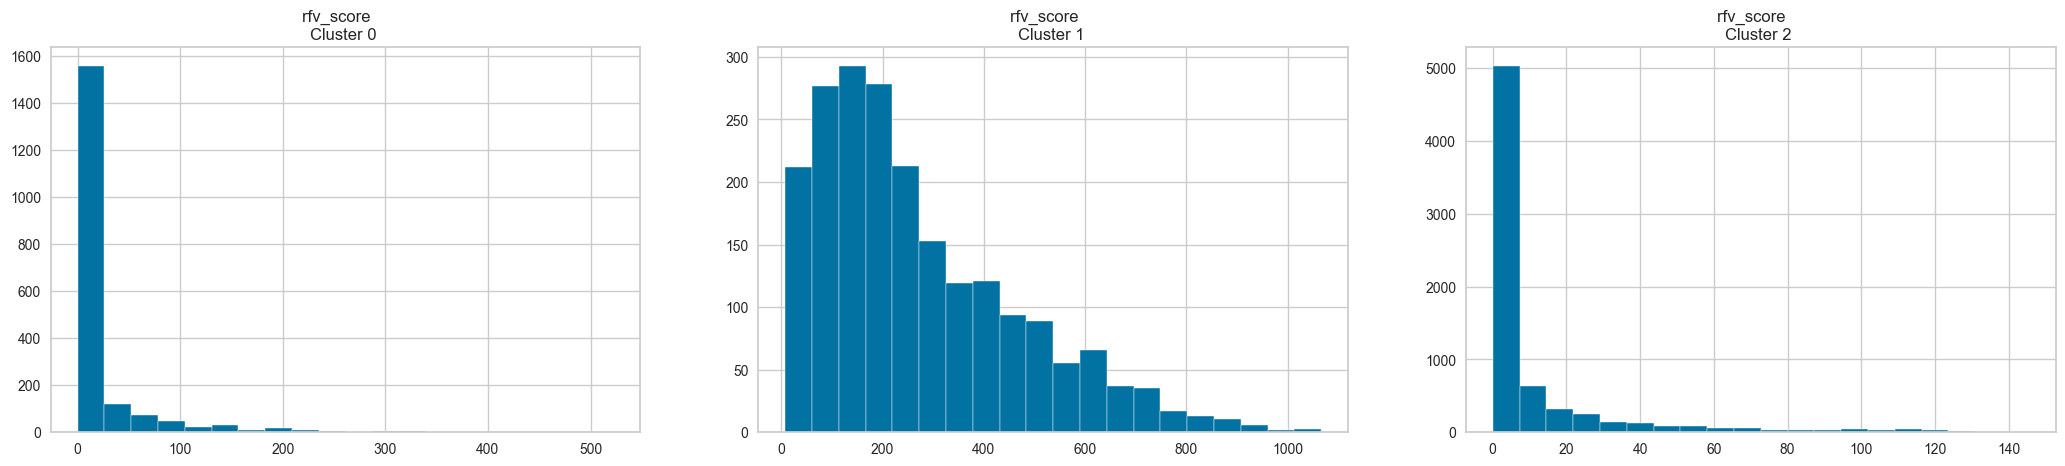

In [36]:
# Plot the histogram of various clusters.
for i in histogram_data.columns:
  plt.figure(figsize = (35, 5))
  for j in range(3):
    plt.subplot(1,4,j+1)
    cluster = clustered_data[clustered_data["cluster"] == str(j)]
    cluster[i].hist(bins = 20)
    plt.title("{}    \nCluster {} ".format(i,j))
  
  plt.show()